In [ ]:
!pip install xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
df = pd.read_excel(
    "Trend Data Combined.ods",
    engine="odf"
)

df = df.dropna(subset=["status"]).copy()

df["status"] = (
    df["status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(df["status"].value_counts())

status
healthy    28
injured     5
Name: count, dtype: int64


In [4]:
health_features = [
    "resting_heart_rate",
    "stress",
    "nightly_hrv",
    "weekly_hrv",
    "sleep_duration",
    "sleep_score",
    "deep_sleep",
    "light_sleep",
    "rem_sleep",
    "awake_duration",
    "hrv_deviation",
    "hr_drift"
]

running_features = [
    "run_count",
    "distance",
    "elapsed_time",
    "weekly_mileage_change_pct",
    "ground_contact_time",
    "cadence",
    "running_heart_rate",
    "elapsed_pace",
    "stride_length",
    "effort_index",
    "chronic_load",
    "max_streak",
    "max_mileage_increase",
    "avg_mileage_change"
]

X_health = df[health_features]
X_running = df[running_features]

y = df["status"].map({
    "healthy": 0,
    "injured": 1
})

print("Health:", X_health.shape)
print("Running:", X_running.shape)
print(y.value_counts())

Health: (33, 12)
Running: (33, 14)
status
0    28
1     5
Name: count, dtype: int64


In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scale_weight = (
    (y == 0).sum() /
    (y == 1).sum()
)

print(
    "scale_pos_weight:",
    scale_weight
)

scale_pos_weight: 5.6


In [6]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",

    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        zero_division=0
    )
}

In [7]:
def run_xgboost(X, y, category_name):

    model = XGBClassifier(
        objective="binary:logistic",

        n_estimators=100,
        max_depth=2,
        learning_rate=0.05,

        scale_pos_weight=scale_weight,

        subsample=0.8,
        colsample_bytree=0.8,

        reg_lambda=1.0,

        eval_metric="logloss",

        random_state=42
    )

    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    print(f"\n{category_name} - XGBoost")
    print("-" * 40)

    for metric in scoring:

        scores = results[
            "test_" + metric
        ]

        print(
            f"{metric}: "
            f"{scores.mean():.3f} +/- "
            f"{scores.std():.3f}"
        )

    y_pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv
    )

    cm = confusion_matrix(
        y,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "Healthy",
            "Injured"
        ]
    )

    disp.plot()

    plt.title(
        f"XGBoost - {category_name}"
    )

    plt.show()

    print(
        classification_report(
            y,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Healthy",
                "Injured"
            ],
            zero_division=0
        )
    )

    return model, results


Health Features - XGBoost
----------------------------------------
accuracy: 0.729 +/- 0.056
balanced_accuracy: 0.430 +/- 0.036
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


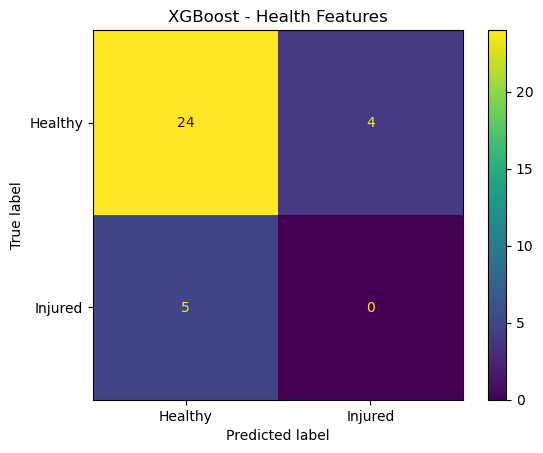

              precision    recall  f1-score   support

     Healthy       0.83      0.86      0.84        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.73        33
   macro avg       0.41      0.43      0.42        33
weighted avg       0.70      0.73      0.71        33



In [8]:
xgb_health, xgb_health_results = run_xgboost(
    X_health,
    y,
    "Health Features"
)


Running Features - XGBoost
----------------------------------------
accuracy: 0.724 +/- 0.114
balanced_accuracy: 0.427 +/- 0.065
precision: 0.000 +/- 0.000
recall: 0.000 +/- 0.000
f1: 0.000 +/- 0.000


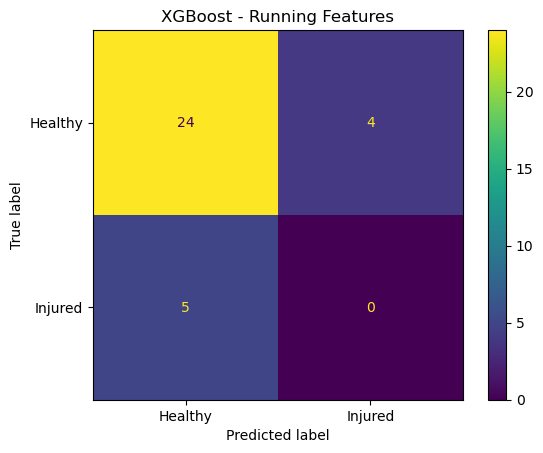

              precision    recall  f1-score   support

     Healthy       0.83      0.86      0.84        28
     Injured       0.00      0.00      0.00         5

    accuracy                           0.73        33
   macro avg       0.41      0.43      0.42        33
weighted avg       0.70      0.73      0.71        33



In [9]:
xgb_running, xgb_running_results = run_xgboost(
    X_running,
    y,
    "Running Features"
)

In [10]:
xgb_health.fit(
    X_health,
    y
)

xgb_running.fit(
    X_running,
    y
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

               Feature  Importance
11            hr_drift    0.114395
7          light_sleep    0.094554
1               stress    0.089247
3           weekly_hrv    0.087522
0   resting_heart_rate    0.086255
4       sleep_duration    0.079834
10       hrv_deviation    0.078665
6           deep_sleep    0.078043
8            rem_sleep    0.077907
9       awake_duration    0.075120
2          nightly_hrv    0.073530
5          sleep_score    0.064929


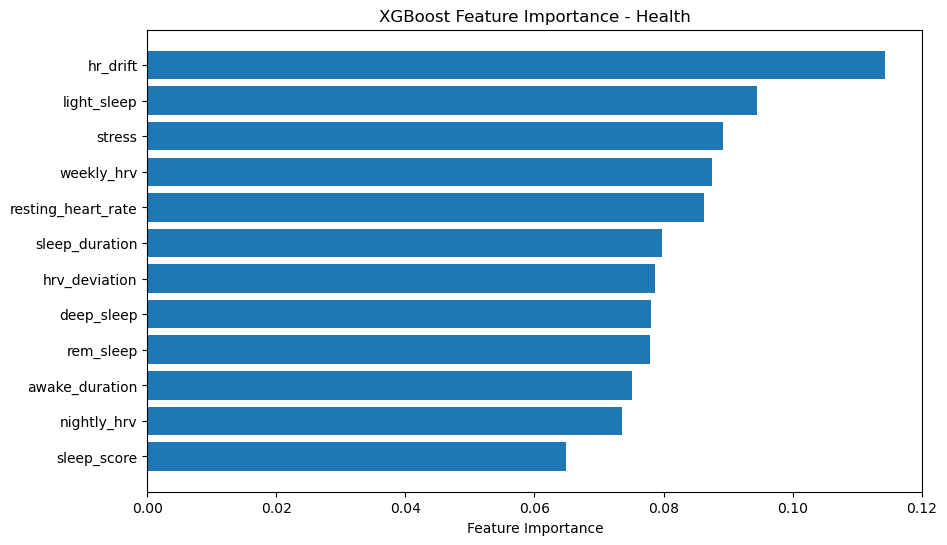

In [11]:
health_importance = pd.DataFrame({
    "Feature": health_features,
    "Importance": xgb_health.feature_importances_
})

health_importance = health_importance.sort_values(
    "Importance",
    ascending=False
)

print(health_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    health_importance["Feature"],
    health_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title(
    "XGBoost Feature Importance - Health"
)

plt.show()

                      Feature  Importance
9                effort_index    0.101443
3   weekly_mileage_change_pct    0.097502
8               stride_length    0.088629
10               chronic_load    0.087610
7                elapsed_pace    0.080732
6          running_heart_rate    0.079033
13         avg_mileage_change    0.077165
4         ground_contact_time    0.072485
12       max_mileage_increase    0.068982
1                    distance    0.065126
0                   run_count    0.062393
5                     cadence    0.049177
2                elapsed_time    0.046471
11                 max_streak    0.023250


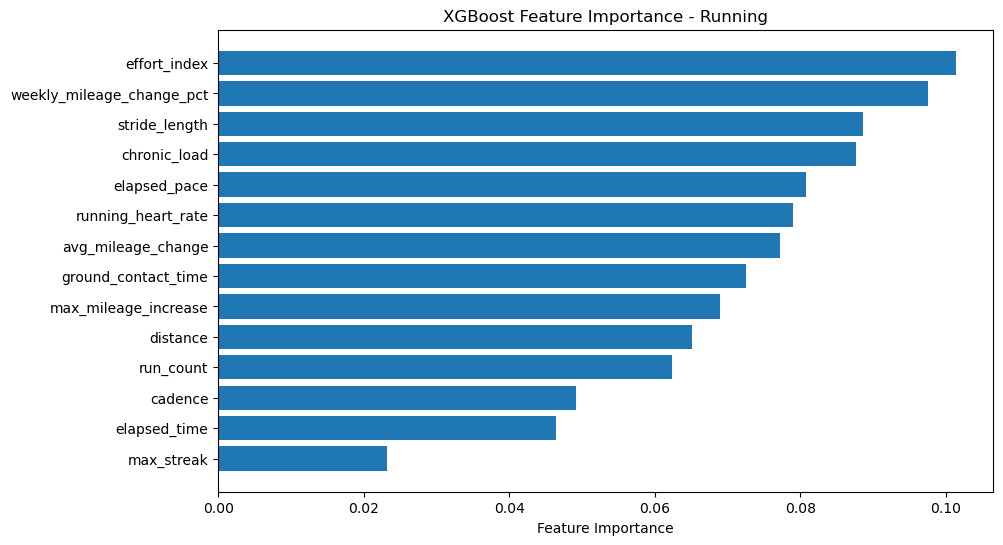

In [12]:
running_importance = pd.DataFrame({
    "Feature": running_features,
    "Importance": xgb_running.feature_importances_
})

running_importance = running_importance.sort_values(
    "Importance",
    ascending=False
)

print(running_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    running_importance["Feature"],
    running_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.title(
    "XGBoost Feature Importance - Running"
)

plt.show()

In [13]:
comparison = pd.DataFrame({
    "Model": [
        "XGBoost - Health",
        "XGBoost - Running"
    ],

    "Accuracy": [
        xgb_health_results[
            "test_accuracy"
        ].mean(),

        xgb_running_results[
            "test_accuracy"
        ].mean()
    ],

    "Balanced Accuracy": [
        xgb_health_results[
            "test_balanced_accuracy"
        ].mean(),

        xgb_running_results[
            "test_balanced_accuracy"
        ].mean()
    ],

    "Injury Precision": [
        xgb_health_results[
            "test_precision"
        ].mean(),

        xgb_running_results[
            "test_precision"
        ].mean()
    ],

    "Injury Recall": [
        xgb_health_results[
            "test_recall"
        ].mean(),

        xgb_running_results[
            "test_recall"
        ].mean()
    ],

    "Injury F1": [
        xgb_health_results[
            "test_f1"
        ].mean(),

        xgb_running_results[
            "test_f1"
        ].mean()
    ]
})

display(comparison.round(3))

,Model,Accuracy,Balanced Accuracy,Injury Precision,Injury Recall,Injury F1
0,XGBoost - Health,0.729,0.430,0.0,0.0,0.0
1,XGBoost - Running,0.724,0.427,0.0,0.0,0.0
